# Principal Component Analysis: compressing images of digits

**Goal.** Describe data with fewer new features while keeping most of the information.

**The method.** PCA finds orthogonal directions of maximum variance. They are the eigenvectors of the covariance matrix,
and each eigenvalue tells how much variance its direction holds.

**The dataset.** *Optical Recognition of Handwritten Digits* (UCI): images of 8x8 pixels, so 64 features per sample.

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "optdigits"
archive = download("https://archive.ics.uci.edu/static/public/80/optical+recognition+of+handwritten+digits.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Already downloaded: data\optdigits\dataset.zip
Files: ['dataset.zip', 'optdigits-orig.cv.Z', 'optdigits-orig.names', 'optdigits-orig.tra.Z', 'optdigits-orig.wdep.Z', 'optdigits-orig.windep.Z', 'optdigits.names', 'optdigits.tes', 'optdigits.tra', 'readme.txt']


In [4]:
import pandas as pd

# 64 features: an 8x8 image, each cell counting the ink from 0 to 16. Column 64 is the digit.
train = pd.read_csv(DATA_DIR / "optdigits.tra", header=None)
test = pd.read_csv(DATA_DIR / "optdigits.tes", header=None)
X_train, y_train = train.iloc[:, :64].to_numpy(), train.iloc[:, 64].to_numpy()
X_test, y_test = test.iloc[:, :64].to_numpy(), test.iloc[:, 64].to_numpy()
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (3823, 64) Test: (1797, 64)


## 2. How much variance does each component hold?

In [5]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)

pca = PCA().fit(Z_train)   # fitted on training data only
cumulative = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
print("Components needed for 95% of the variance:", n95, "of", X_train.shape[1])

Components needed for 95% of the variance: 41 of 64


## 3. Does compression hurt a classifier?
We train the same KNN classifier on a growing number of components.

In [6]:
from sklearn.neighbors import KNeighborsClassifier

components = [2, 5, 10, 15, 20, 30, 40, n95, 64]
components = sorted(set(min(c, 62) for c in components))
scores = []
for c in components:
    reducer = PCA(n_components=c).fit(Z_train)
    knn = KNeighborsClassifier(3).fit(reducer.transform(Z_train), y_train)
    scores.append(knn.score(reducer.transform(Z_test), y_test))
    print(f"{c:3d} components -> test accuracy {scores[-1]:.4f}")

accuracy_full = KNeighborsClassifier(3).fit(Z_train, y_train).score(Z_test, y_test)
accuracy_95 = scores[components.index(n95)]
print("All original features:", round(accuracy_full, 4))

  2 components -> test accuracy 0.5103


  5 components -> test accuracy 0.8175


 10 components -> test accuracy 0.9265


 15 components -> test accuracy 0.9544


 20 components -> test accuracy 0.9610
 30 components -> test accuracy 0.9572
 40 components -> test accuracy 0.9610


 41 components -> test accuracy 0.9622
 62 components -> test accuracy 0.9649


All original features: 0.9649


## 4. Visualize

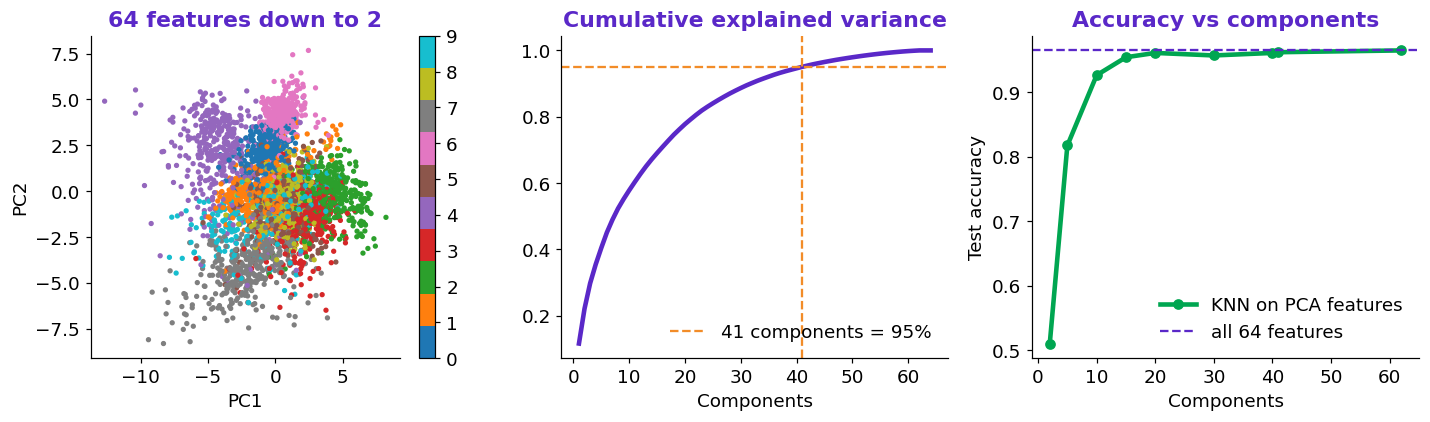

In [7]:
points = PCA(n_components=2).fit_transform(Z_train)

# Reconstruct one digit from only a few components, to see what compression keeps.
sample = Z_test[:1]
panels = []
for c in (2, 10, n95, 62):
    reducer = PCA(n_components=c).fit(Z_train)
    panels.append(scaler.inverse_transform(reducer.inverse_transform(reducer.transform(sample)))[0].reshape(8, 8))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
scatter = ax[0].scatter(points[:, 0], points[:, 1], c=y_train, cmap="tab10", s=6)
ax[0].set(title="64 features down to 2", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=ax[0], ticks=range(10))

ax[1].plot(range(1, 65), cumulative, color=PURPLE, lw=3)
ax[1].axhline(0.95, color=ORANGE, ls="--")
ax[1].axvline(n95, color=ORANGE, ls="--", label=f"{n95} components = 95%")
ax[1].set(title="Cumulative explained variance", xlabel="Components")
ax[1].legend(loc="lower right")

ax[2].plot(components, scores, color=GREEN, lw=3, marker="o", label="KNN on PCA features")
ax[2].axhline(accuracy_full, color=PURPLE, ls="--", label="all 64 features")
ax[2].set(title="Accuracy vs components", xlabel="Components", ylabel="Test accuracy")
ax[2].legend(loc="lower right")
fig.tight_layout()
plt.show()

In [8]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "08_pca.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "PCA + KNN",
    "dataset": "Optical Digits (UCI)",
    "n_samples": int(len(X_train) + len(X_test)),
    "metrics": {"Components for 95%": n95, "Accuracy (all 64)": round(float(accuracy_full), 4), "Accuracy (95% var)": round(float(accuracy_95), 4), "Accuracy (2 comp.)": round(float(scores[0]), 4)},
}
(results_dir / "08_pca.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "PCA + KNN",
  "dataset": "Optical Digits (UCI)",
  "n_samples": 5620,
  "metrics": {
    "Components for 95%": 41,
    "Accuracy (all 64)": 0.9649,
    "Accuracy (95% var)": 0.9622,
    "Accuracy (2 comp.)": 0.5103
  }
}


## What to remember
- PCA is unsupervised: it ignores labels, so the highest-variance direction is not always the most useful.
- Fit PCA on the training set only.